<a href="https://colab.research.google.com/github/snehag77/Recipe-Generator/blob/main/03_ner_bert.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q keras-hub transformers seqeval

import os
os.environ["KERAS_BACKEND"] = "tensorflow"

import json, re, math, random
from collections import Counter
import numpy as np
import tensorflow as tf, keras, keras_hub
from transformers import AutoTokenizer
from seqeval.metrics import classification_report, f1_score
from google.colab import drive

drive.mount("/content/drive")
BASE = "/content/drive/MyDrive/P45_recipe_gen"
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

def load_jsonl(name):
    with open(f"{BASE}/data/{name}.jsonl") as f:
        return [json.loads(l) for l in f]

train_recs, val_recs, test_recs = load_jsonl("train"), load_jsonl("val"), load_jsonl("test")
print(len(train_recs), len(val_recs), len(test_recs))

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
Mounted at /content/drive
27000 1500 1500


In [2]:
LABELS = ["O", "B-FOOD", "I-FOOD", "B-QTY", "I-QTY", "B-UNIT"]
L2I = {l: i for i, l in enumerate(LABELS)}

TOKEN_RE = re.compile(r"\d+\s*/\s*\d+|\d+(?:\.\d+)?|[A-Za-z]+|[^\w\s]")
NUM_RE = re.compile(r"^\d+(\.\d+)?$|^\d+/\d+$")

def pretok(s):
    return [t.replace(" ", "") for t in TOKEN_RE.findall(s.lower())]

UNITS = {"c","cup","cups","tbsp","tablespoon","tablespoons","tsp","teaspoon","teaspoons",
         "oz","ounce","ounces","lb","lbs","pound","pounds","g","gram","grams","kg","ml","l",
         "liter","litre","pkg","package","can","cans","jar","stick","sticks","pinch","dash",
         "clove","cloves","slice","slices","pt","qt","gal","carton","box","bottle",
         "piece","pieces","bunch"}

def label_tokens(tokens, foods):
    labels = ["O"] * len(tokens)
    # 1) food spans first (so "cloves" the spice isn't mistaken for a unit)
    for f in foods:
        ft = pretok(f)
        n = len(ft)
        if n == 0: continue
        for i in range(len(tokens) - n + 1):
            if tokens[i:i+n] == ft and all(l == "O" for l in labels[i:i+n]):
                labels[i] = "B-FOOD"
                for j in range(i + 1, i + n): labels[j] = "I-FOOD"
                break
    # 2) quantities and units on what's left
    prev_qty = False
    for i, t in enumerate(tokens):
        if labels[i] != "O":
            prev_qty = False; continue
        if NUM_RE.match(t):
            labels[i] = "I-QTY" if prev_qty else "B-QTY"; prev_qty = True
        else:
            prev_qty = False
            if t in UNITS: labels[i] = "B-UNIT"
    return labels

# quick test
t = pretok("1 1/2 c. firmly packed brown sugar")
print(list(zip(t, label_tokens(t, ["brown sugar"]))))

[('1', 'B-QTY'), ('1/2', 'I-QTY'), ('c', 'B-UNIT'), ('.', 'O'), ('firmly', 'O'), ('packed', 'O'), ('brown', 'B-FOOD'), ('sugar', 'I-FOOD')]


In [3]:
UNIT_SWAP = {"c.": ["cup", "cups"], "tbsp.": ["tablespoon", "tablespoons"],
             "tsp.": ["teaspoon", "teaspoons"], "lb.": ["pound", "pounds"],
             "oz.": ["ounce", "ounces"]}

def augment_units(line):
    line = line.lower()
    for k, vs in UNIT_SWAP.items():
        if random.random() < 0.5:
            line = re.sub(rf"(?<!\w){re.escape(k)}", random.choice(vs), line)
    return line

def build_examples(records, max_lines, augment=False):
    out = []
    for r in records:
        for line in r["ingredients"]:
            if augment: line = augment_units(line)
            toks = pretok(line)
            if not 1 < len(toks) <= 40: continue
            labs = label_tokens(toks, r["NER"])
            if any(l == "B-FOOD" for l in labs):          # keep only lines with a food match
                out.append((toks, labs))
            if len(out) >= max_lines: return out
    return out

train_ex = build_examples(train_recs, 60_000, augment=True)
val_ex   = build_examples(val_recs, 4_000)
test_ex  = build_examples(test_recs, 4_000)

# synthetic lines: metric units and free-text style, like what a user would type
freq = Counter(n for r in train_recs for n in r["NER"])
FOODS = [n for n, c in freq.items() if c >= 20 and len(pretok(n)) <= 3]
QS = ["1", "2", "3", "4", "1/2", "1.5", "100", "250", "500"]
SYN_UNITS = ["g", "kg", "ml", "l", "grams", "cup", "cups", "tbsp", "tsp", "pinch", "cloves", "slices", "pieces"]
PRE = [[], [], ["chopped"], ["fresh"], ["some"], ["diced"], ["ground"]]

def synth(n):
    out = []
    for _ in range(n):
        ft = pretok(random.choice(FOODS)); pre = random.choice(PRE)
        food_labs = ["B-FOOD"] + ["I-FOOD"] * (len(ft) - 1)
        if random.random() < 0.7:
            u = random.choice(SYN_UNITS) if random.random() < 0.8 else None
            toks = [random.choice(QS)] + ([u] if u else []) + pre + ft
            labs = ["B-QTY"] + (["B-UNIT"] if u else []) + ["O"] * len(pre) + food_labs
        else:
            toks = pre + ft; labs = ["O"] * len(pre) + food_labs
        out.append((toks, labs))
    return out

train_ex += synth(8_000)
random.shuffle(train_ex)
print(len(train_ex), len(val_ex), len(test_ex))
print(train_ex[0])

label_counts = Counter(l for _, labs in train_ex for l in labs)
print(label_counts)

68000 4000 4000
(['3', 'eggs'], ['B-QTY', 'B-FOOD'])
Counter({'O': 100470, 'B-FOOD': 68160, 'B-QTY': 67720, 'B-UNIT': 57106, 'I-FOOD': 32181, 'I-QTY': 3415})


In [4]:
MAXLEN = 48
tok = AutoTokenizer.from_pretrained("bert-base-uncased")

def encode(examples):
    words = [e[0] for e in examples]
    enc = tok(words, is_split_into_words=True, truncation=True,
              max_length=MAXLEN, padding="max_length", return_tensors="np")
    labels = np.full((len(examples), MAXLEN), -100, dtype=np.int32)
    for i, (_, labs) in enumerate(examples):
        prev = None
        for pos, wid in enumerate(enc.word_ids(i)):
            if wid is not None and wid != prev:
                labels[i, pos] = L2I[labs[wid]]
            prev = wid
    return {
        "token_ids": enc["input_ids"].astype(np.int32),
        "segment_ids": np.zeros((len(examples), MAXLEN), dtype=np.int32),
        "padding_mask": enc["attention_mask"].astype(np.int32),
    }, labels

BATCH = 32
def make_ds(examples, shuffle=False):
    x, y = encode(examples)
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if shuffle: ds = ds.shuffle(20_000, seed=SEED)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(train_ex, True), make_ds(val_ex), make_ds(test_ex)
xb, yb = next(iter(train_ds))
print({k: v.shape for k, v in xb.items()}, yb.shape)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

{'token_ids': TensorShape([32, 48]), 'segment_ids': TensorShape([32, 48]), 'padding_mask': TensorShape([32, 48])} (32, 48)


In [5]:
def build_ner_model():
    backbone = keras_hub.models.BertBackbone.from_preset("bert_base_en_uncased")
    inputs = {
        "token_ids": keras.Input((MAXLEN,), dtype="int32", name="token_ids"),
        "segment_ids": keras.Input((MAXLEN,), dtype="int32", name="segment_ids"),
        "padding_mask": keras.Input((MAXLEN,), dtype="int32", name="padding_mask"),
    }
    seq = backbone(inputs)["sequence_output"]
    x = keras.layers.Dropout(0.1)(seq)
    logits = keras.layers.Dense(len(LABELS), name="ner_head")(x)
    return keras.Model(inputs, logits, name="bert_ner")

model = build_ner_model()
model.summary(line_length=90)

Model: "bert_ner"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)             ┃ Output Shape         ┃      Param # ┃ Connected to          ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━┩
│ padding_mask             │ (None, 48)           │            0 │ -                     │
│ (InputLayer)             │                      │              │                       │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ segment_ids (InputLayer) │ (None, 48)           │            0 │ -                     │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ token_ids (InputLayer)   │ (None, 48)           │            0 │ -                     │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ bert_backbone            │ [(None, 768), (None, │  109,482,240 │ padding_mask[0][0],   │
│ (BertBackbone)           │ 48, 768)]            │              │ segment_ids[0][0],    │
│                          │                      │              │ token_ids[0][0]       │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ dropout_12 (Dropout)     │ (None, 48, 768)      │            0 │ bert_backbone[0][1]   │
├──────────────────────────┼──────────────────────┼──────────────┼───────────────────────┤
│ ner_head (Dense)         │ (None, 48, 6)        │        4,614 │ dropout_12[0][0]      │
└──────────────────────────┴──────────────────────┴──────────────┴───────────────────────┘

 Total params: 109,486,854 (417.66 MB)

 Trainable params: 109,486,854 (417.66 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
EPOCHS = 3
steps_per_epoch = math.ceil(len(train_ex) / BATCH)
total_steps = steps_per_epoch * EPOCHS
warmup = int(0.06 * total_steps)

lr_schedule = keras.optimizers.schedules.CosineDecay(
    0.0, decay_steps=total_steps - warmup, warmup_target=3e-5,
    warmup_steps=warmup, alpha=0.05)
optimizer = keras.optimizers.AdamW(learning_rate=lr_schedule, weight_decay=0.01)

@tf.function
def train_step(x, y):
    mask = tf.cast(y != -100, tf.float32)
    y_safe = tf.where(y == -100, 0, y)
    with tf.GradientTape() as tape:
        logits = model(x, training=True)
        per_tok = keras.losses.sparse_categorical_crossentropy(y_safe, logits, from_logits=True)
        loss = tf.reduce_sum(per_tok * mask) / tf.maximum(tf.reduce_sum(mask), 1.0)
    grads = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(grads, model.trainable_variables))
    preds = tf.argmax(logits, axis=-1, output_type=tf.int32)
    correct = tf.reduce_sum(tf.cast(preds == y_safe, tf.float32) * mask)
    return loss, correct, tf.reduce_sum(mask)

@tf.function
def eval_step(x, y):
    mask = tf.cast(y != -100, tf.float32)
    y_safe = tf.where(y == -100, 0, y)
    logits = model(x, training=False)
    per_tok = keras.losses.sparse_categorical_crossentropy(y_safe, logits, from_logits=True)
    loss = tf.reduce_sum(per_tok * mask)
    preds = tf.argmax(logits, axis=-1, output_type=tf.int32)
    correct = tf.reduce_sum(tf.cast(preds == y_safe, tf.float32) * mask)
    return loss, correct, tf.reduce_sum(mask)

history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
for epoch in range(EPOCHS):
    tl = tc = tn = 0.0
    for step, (x, y) in enumerate(train_ds):
        l, c, n = train_step(x, y)
        tl += float(l) * float(n); tc += float(c); tn += float(n)
        if step % 300 == 0:
            print(f"epoch {epoch+1} step {step}/{steps_per_epoch} loss {float(l):.4f}")
    vl = vc = vn = 0.0
    for x, y in val_ds:
        l, c, n = eval_step(x, y)
        vl += float(l); vc += float(c); vn += float(n)
    history["train_loss"].append(tl / tn); history["train_acc"].append(tc / tn)
    history["val_loss"].append(vl / vn);   history["val_acc"].append(vc / vn)
    print(f"== epoch {epoch+1}: train loss {tl/tn:.4f} acc {tc/tn:.4f} | val loss {vl/vn:.4f} acc {vc/vn:.4f}")
    model.save_weights(f"{BASE}/checkpoints/ner_bert_epoch{epoch+1}.weights.h5")

json.dump(history, open(f"{BASE}/outputs/ner_history.json", "w"))

/usr/local/lib/python3.13/dist-packages/keras/src/optimizers/base_optimizer.py:870: UserWarning: Gradients do not exist for variables ['pooled_dense/kernel', 'pooled_dense/bias'] when minimizing the loss. If using `model.compile()`, did you forget to provide a `loss` argument?
  warnings.warn(


epoch 1 step 0/2125 loss 1.9468
epoch 1 step 300/2125 loss 0.1317
epoch 1 step 600/2125 loss 0.0381
epoch 1 step 900/2125 loss 0.1702
epoch 1 step 1200/2125 loss 0.1313
epoch 1 step 1500/2125 loss 0.0987
epoch 1 step 1800/2125 loss 0.0804
epoch 1 step 2100/2125 loss 0.0563
== epoch 1: train loss 0.1584 acc 0.9425 | val loss 0.0674 acc 0.9758
epoch 2 step 0/2125 loss 0.0675
epoch 2 step 300/2125 loss 0.1137
epoch 2 step 600/2125 loss 0.0400
epoch 2 step 900/2125 loss 0.0746
epoch 2 step 1200/2125 loss 0.0816
epoch 2 step 1500/2125 loss 0.0089
epoch 2 step 1800/2125 loss 0.0219
epoch 2 step 2100/2125 loss 0.1088
== epoch 2: train loss 0.0571 acc 0.9794 | val loss 0.0515 acc 0.9815
epoch 3 step 0/2125 loss 0.0163
epoch 3 step 300/2125 loss 0.0644
epoch 3 step 600/2125 loss 0.0601
epoch 3 step 900/2125 loss 0.0207
epoch 3 step 1200/2125 loss 0.0141
epoch 3 step 1500/2125 loss 0.0671
epoch 3 step 1800/2125 loss 0.0717
epoch 3 step 2100/2125 loss 0.0163
== epoch 3: train loss 0.0358 acc 0.98

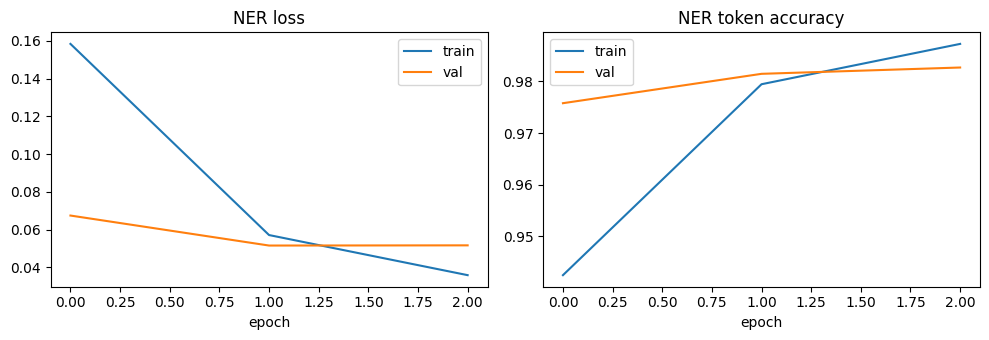

In [7]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(history["train_loss"], label="train"); ax[0].plot(history["val_loss"], label="val")
ax[0].set_title("NER loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history["train_acc"], label="train"); ax[1].plot(history["val_acc"], label="val")
ax[1].set_title("NER token accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{BASE}/outputs/ner_curves.png", dpi=150); plt.show()

In [8]:
def predict_word_labels(ds):
    y_true, y_pred = [], []
    for x, y in ds:
        preds = tf.argmax(model(x, training=False), axis=-1).numpy()
        y = y.numpy()
        for yi, pi in zip(y, preds):
            keep = yi != -100
            y_true.append([LABELS[i] for i in yi[keep]])
            y_pred.append([LABELS[i] for i in pi[keep]])
    return y_true, y_pred

y_true, y_pred = predict_word_labels(test_ds)
report = classification_report(y_true, y_pred, digits=3)
print(report)
print("Entity-level F1:", round(f1_score(y_true, y_pred), 4))

json.dump({"f1": f1_score(y_true, y_pred),
           "report": classification_report(y_true, y_pred, output_dict=True)},
          open(f"{BASE}/outputs/ner_metrics.json", "w"), indent=2, default=float)

              precision    recall  f1-score   support

        FOOD      0.948     0.951     0.949      4010
         QTY      1.000     1.000     1.000      4146
        UNIT      0.999     1.000     0.999      3540

   micro avg      0.982     0.983     0.982     11696
   macro avg      0.982     0.983     0.983     11696
weighted avg      0.982     0.983     0.982     11696

Entity-level F1: 0.9824


In [10]:
def tag_text(text):
    words = pretok(text)
    enc = tok([words], is_split_into_words=True, truncation=True,
              max_length=MAXLEN, padding="max_length", return_tensors="np")
    x = {"token_ids": enc["input_ids"].astype(np.int32),
         "segment_ids": np.zeros((1, MAXLEN), dtype=np.int32),
         "padding_mask": enc["attention_mask"].astype(np.int32)}
    pred = tf.argmax(model(x, training=False), axis=-1).numpy()[0]
    labs, prev = ["O"] * len(words), None
    for pos, wid in enumerate(enc.word_ids(0)):
        if wid is not None and wid != prev:
            labs[wid] = LABELS[pred[pos]]
        prev = wid
    return words, labs

def extract_entities(text):
    words, labs = tag_text(text)
    groups, cur = {"FOOD": [], "QTY": [], "UNIT": []}, None
    for w, l in zip(words, labs):
        if l == "O":
            cur = None; continue
        bio, typ = l.split("-")
        if bio == "B" or cur is None or cur[0] != typ:
            cur = [typ, [w]]; groups[typ].append(cur[1])
        else:
            cur[1].append(w)
    return {k: [" ".join(v) for v in vs] for k, vs in groups.items()}

In [11]:
tests = [
    "2 cups basmati rice and some chopped onions",
    "chicken, rice, garlic, soy sauce",
    "250 g paneer, 1 tsp cumin seeds, 2 tomatoes",
    "1/2 cup peanut butter and 3 tbsp honey",
    "500 g flour, 100 g butter, 2 eggs, a pinch of salt",
]
for t in tests:
    print(t, "->", extract_entities(t))

2 cups basmati rice and some chopped onions -> {'FOOD': ['basmati rice'], 'QTY': ['2'], 'UNIT': ['cups']}
chicken, rice, garlic, soy sauce -> {'FOOD': ['chicken'], 'QTY': [], 'UNIT': []}
250 g paneer, 1 tsp cumin seeds, 2 tomatoes -> {'FOOD': ['paneer'], 'QTY': ['250', '1', '2'], 'UNIT': ['g', 'tsp']}
1/2 cup peanut butter and 3 tbsp honey -> {'FOOD': ['peanut butter'], 'QTY': ['1/2', '3'], 'UNIT': ['cup', 'tbsp']}
500 g flour, 100 g butter, 2 eggs, a pinch of salt -> {'FOOD': ['flour'], 'QTY': ['500', '100', '2'], 'UNIT': ['g', 'g', 'pinch']}


In [13]:
model.save_weights(f"{BASE}/checkpoints/ner_bert_final.weights.h5")
json.dump({"labels": LABELS, "maxlen": MAXLEN, "tokenizer": "bert-base-uncased",
           "backbone": "bert_base_en_uncased"},
          open(f"{BASE}/checkpoints/ner_config.json", "w"))